# Notebook 1: can we predict whether a failed CI job is a fluke?

**How to use this notebook.** Run one cell at a time (Shift+Enter), top to bottom. Before running a cell, read the text above it and guess what will happen. After it runs, check your guess.

Boxes called **Think** are questions for you. Write your answer in the cell below each one (double-click the text to edit it). Those answers become the discussion section of your report.

**Vocabulary used here**
- *transient* = the failed job passed when re-run (`y = 1`)
- *real* = the job failed again when re-run (`y = 0`)
- *PR-AUC* = a score from 0 to 1 for how well the model ranks the right jobs first (explained in Step 5)

## Step 0: Load the dataset
Run this from the folder that contains `data/` and `baselines.py` (`D:\Projects\ci-flaky-project`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140, "display.max_colwidth", 80)

df = pd.read_parquet("data/dataset.parquet")
print(df.shape)
df.head(3)

(3222, 40)


,repo,language,run_id,job_id,workflow,job_name,job_name_norm,event,head_branch,run_created_at,...,wf_fail_7d,wf_fail_rate_7d,n_failed_jobs_in_run,main_set,label,label_detail,y,later_attempts,run_attempts_total,sample_group
0,App-vNext/Polly,C#,33894128530,101092616028,build,ubuntu-latest,ubuntu-latest,pull_request,dependabot/nuget/dot-config/sign-0.9.1-beta.26431.1,2026-09-04 16:15:37+00:00,...,1,0.125,1,True,passed_on_rerun,transient_other,1.0,[success],2,rerun_run
1,App-vNext/Polly,C#,33893271563,101089819059,build,windows-latest,windows-latest,pull_request,dependabot/github_actions/azure/login-3.0.2,2026-09-04 16:06:29+00:00,...,1,0.125,1,True,passed_on_rerun,transient_other,1.0,[success],2,rerun_run
2,App-vNext/Polly,C#,34847438902,103986725385,Automatic Dependency Submission (NuGet),submit-nuget,submit-nuget,dynamic,changelog-8.8.0,2026-09-14 13:09:00+00:00,...,1,0.020,1,True,passed_on_rerun,transient_other,1.0,[success],2,rerun_run


## Step 1: What is one row, and what must the model never see?

One row is **one failed job**. The column `y` is the answer we want to predict. Some columns contain the answer, or a hint of it, in disguise. If the model sees them it cheats, and our results become meaningless. The cell below lists them.

In [3]:
never_use = ["label", "label_detail", "y", "later_attempts", "run_attempts_total",
             "sample_group", "log_status", "has_log"]
df[never_use].head(5)

,label,label_detail,y,later_attempts,run_attempts_total,sample_group,log_status,has_log
0,passed_on_rerun,transient_other,1.0,[success],2,rerun_run,ok,True
1,passed_on_rerun,transient_other,1.0,[success],2,rerun_run,ok,True
2,passed_on_rerun,transient_other,1.0,[success],2,rerun_run,ok,True
3,passed_on_rerun,transient_other,1.0,[success],2,rerun_run,ok,True
4,passed_on_rerun,transient_other,1.0,"[failure, failure, failure, success]",5,rerun_run,ok,True


**Think 1.** For each column in the list above, explain in one sentence why it must not be a model input. Two of them (`log_status`, `has_log`) are not about the answer at all. What is wrong with them?

*My answer:*

## Step 2: Which rows do we use?

`main_set` = has a usable label **and** is not a "metadata" job (CLA bot, PR-title check and so on). Those jobs "pass on rerun" because a person fixed something, not because the job was flaky.

In [4]:
data = df[df["main_set"]].reset_index(drop=True)
print(f"all failed jobs: {len(df)}   ->   used for modelling: {len(data)}")
print(data["y"].value_counts().rename({1.0: "transient", 0.0: "real"}))
print("share transient:", round(data["y"].mean(), 3))

all failed jobs: 3222   ->   used for modelling: 2370
y
transient    1778
real          592
Name: count, dtype: int64
share transient: 0.75


## Step 3: The bar to beat

A model that always answers "transient" is right about as often as the share above, and it learns nothing. That is why **accuracy is a bad score here**.

In [5]:
p = data["y"].mean()
print(f"always say 'transient': accuracy = {p:.2f}")
print(f"... but it catches {0} of the {int((data.y==0).sum())} real failures")

always say 'transient': accuracy = 0.75
... but it catches 0 of the 592 real failures


**Think 2.** If we used this "always transient" rule in real life, what would happen to a developer whose job failed for a real reason? Which mistake is more expensive: re-running a job that was really broken, or *not* re-running one that was a fluke? Write down which one you think costs more and why. We will turn your answer into numbers later.

*My answer:*

## Step 4: The most important experiment: random split vs split by project

We train on some rows and test on others. **Which rows go where** changes the score a lot.

- **Random split:** rows from the *same project* land on both sides. The model can memorise "this project is usually flaky".
- **Split by project (GroupKFold):** a project is entirely in train or entirely in test. The model must work on projects it has never seen.

To show the difference, I give both models the project name as a feature and run the same model both ways.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num = ["hour", "weekday", "is_pr", "is_default_branch", "job_duration_s",
       "n_failed_jobs_in_run", "repo_fail_rate_24h", "wf_fail_rate_7d"]
X = data[num + ["repo"]]
y = data["y"].astype(int)

def make():
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("repo", OneHotEncoder(handle_unknown="ignore"), ["repo"])])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000))])

def score(p):
    return average_precision_score(y, p), average_precision_score(1 - y, 1 - p)

p_random = cross_val_predict(make(), X, y, cv=KFold(5, shuffle=True, random_state=0),
                             method="predict_proba")[:, 1]
p_group = cross_val_predict(make(), X, y, cv=GroupKFold(5), groups=data["repo"],
                            method="predict_proba")[:, 1]
print("                       PR-AUC transient   PR-AUC real")
print("random split         :  %.3f              %.3f" % score(p_random))
print("split by project     :  %.3f              %.3f" % score(p_group))
print("random guessing      :  %.3f              %.3f" % (y.mean(), 1 - y.mean()))

                       PR-AUC transient   PR-AUC real
random split         :  0.875              0.483
split by project     :  0.823              0.333
random guessing      :  0.750              0.250


In [1]:
import sys; print(sys.executable)

c:\Users\Administrator\anaconda3\envs\ci-flaky\python.exe


**Think 3.** Compare the two rows. Which one is higher, and why? Which one should you put in your report as the honest estimate for a *new* project? What would a reviewer say if you reported the other one?

*My answer:*

## Step 5: One model, built slowly

Now the model we will actually use. The pipeline has three parts, and everything it learns comes **only from the training rows**:

1. numbers: fill gaps with the median, then rescale
2. categories (event, operating system): turn into 0/1 columns
3. text (job name and error lines): TF-IDF turns text into numbers, giving high weight to words that are frequent in a job but rare elsewhere

Then logistic regression learns one weight per column.

In [7]:
from baselines import load_main, GROUPS, make_model, columns_of
data = load_main()                       # same rows as before, plus a leakage check
all_groups = list(GROUPS)

tr_idx, te_idx = next(GroupKFold(5).split(data, groups=data["repo"]))
train, test = data.iloc[tr_idx], data.iloc[te_idx]
print("train projects:", train.repo.nunique(), " test projects:", test.repo.nunique(),
      " overlap:", len(set(train.repo) & set(test.repo)))

model = make_model("logreg", all_groups, data.columns)
model.fit(train, train["y"].astype(int))
proba = model.predict_proba(test)[:, 1]
pd.DataFrame({"job": test["job_name"].values[:8], "P(transient)": proba[:8].round(2),
              "truth": test["y"].values[:8]})

train projects: 21  test projects: 4  overlap: 0


,job,P(transient),truth
0,"macos-26, Xcode 26.5, Ruby 3.4 Tests",0.80,1.0
1,"Split, Windows",0.90,1.0
2,"macos-26, Xcode 26.6, Ruby 4.0 Tests",0.90,1.0
3,"Split, Windows",0.86,1.0
4,"macos-15, Xcode 16.4.0, Ruby 3.3 Tests",0.87,1.0
5,create_github_release,0.56,0.0
6,"macos-15, Xcode 16.4.0, Ruby 3.4 Tests",0.80,1.0
7,communicate on pull request merged,0.98,1.0


Each row above is a probability. 0.90 means "I am 90% sure this was a fluke".

**What did it learn?** The cell below shows the words and features with the biggest weights. Positive weights push towards "transient", negative towards "real".

In [8]:
names = model.named_steps["pre"].get_feature_names_out()
w = model.named_steps["clf"].coef_[0]
order = np.argsort(w)
print("pushes towards REAL     :", [names[i] for i in order[:12]])
print("pushes towards TRANSIENT:", [names[i] for i in order[::-1][:12]])

pushes towards REAL     : ['cat__event_workflow_dispatch', 'txt_job_name_norm__build docs', 'txt_job_name_norm__bit', 'txt_job_name_norm__docs', 'txt_job_name_norm__spell', 'txt_job_name_norm__spell check', 'txt_job_name_norm__arm nightlies', 'txt_job_name_norm__run_tests', 'txt_log_errors__is', 'txt_job_name_norm__check', 'txt_job_name_norm__boringssl test', 'txt_job_name_norm__unit']
pushes towards TRANSIENT: ['cat__event_workflow_run', 'txt_job_name_norm__ci', 'txt_job_name_norm__cypress', 'txt_job_name_norm__prerequisites', 'txt_job_name_norm__check cypress', 'txt_job_name_norm__cypress prerequisites', 'txt_log_errors__fail error', 'txt_log_errors__http', 'txt_job_name_norm__fuzzing', 'txt_job_name_norm__blocks', 'txt_job_name_norm__docker', 'txt_job_name_norm__aggregate_test_result']


**Think 4.** Look at the lists. Do they make sense (for example, are error words like *timeout* or *network* on the transient side)? Are any of them suspicious, such as a project-specific word that would not help on a new project? Name one feature that surprises you.

*My answer:*

## Step 6: Reading the scores

- **PR-AUC (transient):** sort jobs by P(transient). If the top of the list is full of real transients, the score is near 1. Random guessing scores the share of transients.
- **PR-AUC (real):** same, but for finding real failures. This one matters most to us, because calling a real failure a fluke is the costly mistake.
- **Brier / ECE:** are the probabilities honest? When the model says 70%, is it right about 70% of the time?

In [9]:
from baselines import metrics
m = metrics(test["y"], proba)
pd.Series(m).round(3)

n                   470.000
prevalence            0.740
pr_auc_transient      0.848
pr_auc_real           0.394
brier                 0.234
ece                   0.185
roc_auc               0.696
dtype: float64

## Step 7: All models, both test schemes

Now all models on all the data. `unseen_projects` means the model is tested on projects it never saw. `temporal` means it is trained on the earlier jobs and tested on the later ones.

This takes a few minutes. Run it once and leave it.

In [10]:
from baselines import eval_unseen, eval_temporal
rows, oof = [], {}
models = ["dummy", "logreg", "rf", "hgb"]
try:
    import lightgbm; models.append("lgbm")
except Exception:
    print("lightgbm not installed (optional): pip install lightgbm")
for name in models:
    p_, m_ = eval_unseen(data, name, all_groups)
    oof[name] = p_
    rows.append({"scheme": "unseen_projects", "model": name, **m_})
    rows.append({"scheme": "temporal", "model": name, **eval_temporal(data, name, all_groups)})
res = pd.DataFrame(rows)
res.round(3)

,scheme,model,n,prevalence,pr_auc_transient,pr_auc_real,brier,ece,roc_auc
0,unseen_projects,dummy,2370,0.75,0.720,0.226,0.188,0.000,0.438
1,temporal,dummy,711,0.79,0.790,0.210,0.169,0.057,0.500
2,unseen_projects,logreg,2370,0.75,0.823,0.316,0.220,0.120,0.605
3,temporal,logreg,711,0.79,0.868,0.440,0.154,0.068,0.683
4,unseen_projects,rf,2370,0.75,0.797,0.307,0.186,0.030,0.574
5,temporal,rf,711,0.79,0.867,0.421,0.151,0.059,0.637
6,unseen_projects,hgb,2370,0.75,0.755,0.281,0.213,0.141,0.513
7,temporal,hgb,711,0.79,0.857,0.360,0.170,0.084,0.631
8,unseen_projects,lgbm,2370,0.75,0.760,0.284,0.228,0.171,0.522
9,temporal,lgbm,711,0.79,0.870,0.377,0.171,0.098,0.664


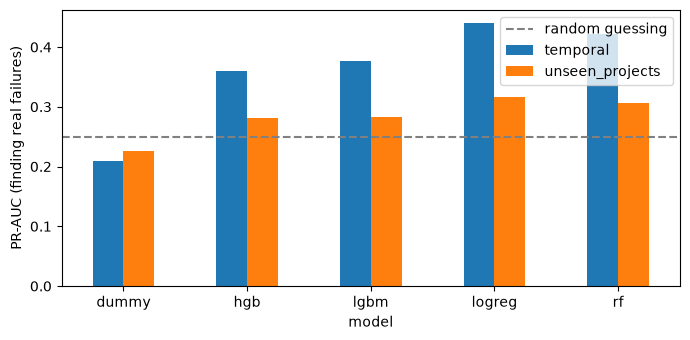

In [11]:
piv = res.pivot(index="model", columns="scheme", values="pr_auc_real")
ax = piv.plot.bar(figsize=(7, 3.5), rot=0)
ax.axhline(1 - data.y.mean(), ls="--", c="gray", label="random guessing")
ax.set_ylabel("PR-AUC (finding real failures)"); ax.legend(); plt.tight_layout()
import os; os.makedirs("results", exist_ok=True); plt.savefig("results/models_pr_auc_real.png", dpi=150)

**Think 5.** (a) Do the models beat `dummy`? By how much? A gain below about 0.02 is probably noise. (b) Is the simplest model (`logreg`) much worse than the complex ones? (c) Are the `temporal` numbers higher or lower than `unseen_projects`? Why might that be?

Remember: if you see a score near 1.0, suspect leakage before you celebrate.

*My answer:*

## Step 8: Are the probabilities honest? (calibration)

Take all the jobs where the model said "about 80% transient". If the model is honest, about 80% of them were transient. The curve below checks that. The closer it is to the diagonal, the better.

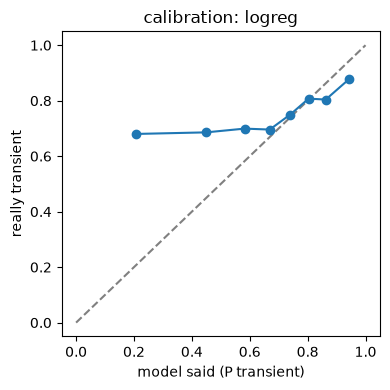

In [12]:
from sklearn.calibration import calibration_curve
best = res[res.scheme == "unseen_projects"].sort_values("pr_auc_real", ascending=False).model.iloc[0]
best = best if best != "dummy" else "logreg"
frac, mean_p = calibration_curve(data["y"], oof[best], n_bins=8, strategy="quantile")
plt.figure(figsize=(4, 4)); plt.plot([0, 1], [0, 1], "--", c="gray")
plt.plot(mean_p, frac, "o-"); plt.xlabel("model said (P transient)"); plt.ylabel("really transient")
plt.title(f"calibration: {best}"); plt.tight_layout(); plt.savefig("results/calibration.png", dpi=150)

**Think 6.** Is the curve above or below the diagonal in places? What would that mean for a developer who trusts "90% sure it is a fluke" and re-runs automatically? (We fix miscalibration in the next notebook.)

*My answer:*

## Step 9: Which kind of information matters? (ablation)

An *ablation* removes one group of features at a time to see how much the score drops. The groups are `context`, `job`, `history`, `run` and `log`. A group that can be removed without losing anything is not helping.

In [13]:
ab = []
_, full = eval_unseen(data, "logreg", all_groups)
ab.append({"setting": "all groups", **full})
for g in all_groups:
    _, d1 = eval_unseen(data, "logreg", [x for x in all_groups if x != g]); ab.append({"setting": f"drop {g}", **d1})
    _, d2 = eval_unseen(data, "logreg", [g]);                               ab.append({"setting": f"only {g}", **d2})
ab = pd.DataFrame(ab)
ab[["setting", "pr_auc_transient", "pr_auc_real", "roc_auc", "brier"]].round(3)

,setting,pr_auc_transient,pr_auc_real,roc_auc,brier
0,all groups,0.823,0.316,0.605,0.220
1,drop context,0.818,0.329,0.607,0.211
2,only context,0.722,0.265,0.469,0.195
3,drop job,0.824,0.345,0.630,0.198
4,only job,0.720,0.229,0.460,0.206
5,drop history,0.768,0.299,0.536,0.223
6,only history,0.825,0.384,0.628,0.179
7,drop run,0.781,0.283,0.550,0.213
8,only run,0.743,0.291,0.527,0.188
9,drop log,0.825,0.316,0.612,0.220


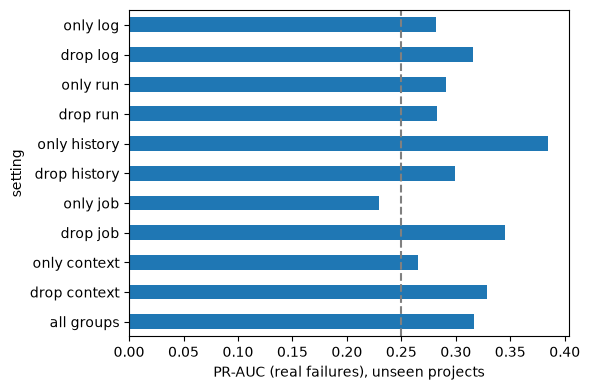

In [14]:
sub = ab.set_index("setting")["pr_auc_real"]
sub.plot.barh(figsize=(6, 4)); plt.axvline(1 - data.y.mean(), ls="--", c="gray")
plt.xlabel("PR-AUC (real failures), unseen projects"); plt.tight_layout()
plt.savefig("results/ablation.png", dpi=150)

**Think 7.** (a) Which group alone is the best? (b) Which group, when dropped, hurts the most? (c) Are they the same group? If not, what does that tell you about overlap between the groups?

*My answer:*

## Step 10: Your conclusions

Write 4–6 sentences in your own words: what worked, what did not, how much you trust it and why. Mention the one thing you would investigate next. This is the part your examiner will ask about.

*My conclusions:*